# 06 Phase 6: final verification (Home Credit test set, once) and UCI Taiwan retrain

**What this shows.** Every arm was scored on the held-out test set exactly once (one guard-log entry per arm; predictions were written to disk at that access and every number below is computed from those saved files). Operating points were chosen on validation before the test run. Every table marks each arm as *deployable* (gender-blind at inference) or *analysis only* (uses gender). Mean over seeds with 95% paired bootstrap CIs (1,000 resamples). The leakage 'after' probe, the SHAP-vector probe, the new-proxy check and the matched-pair check follow, then the Taiwan retrain with identical hyper-parameters and lambdas.

In [1]:
import json, sys, subprocess
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 200)
P6 = ROOT / Path((ROOT / 'artifacts' / 'phase6_rundir.txt').read_text().strip())
R = P6 / 'report'
git = lambda *a: subprocess.run(['git', *a], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print('phase6 run folder:', P6.name); print('HEAD:', git('log', '--oneline', '-1'))

phase6 run folder: 20261101T104908Z_phase6
HEAD: 3ab75f8 disclose three-way points in configurations tried; add rule against closing outside processes; record incident


## 1. Test-set discipline: guard-log audit

In [2]:
audit = json.loads((R / 'guard_audit.json').read_text()); print(json.dumps(audit, indent=1))
assert audit['one_entry_per_arm'], 'guard log does not have exactly one entry per arm'

{
 "n_entries": 28,
 "phase1_whitelisted": 1,
 "phase6_entries": 27,
 "arms_evaluated": 27,
 "one_entry_per_arm": true,
 "missing": [],
 "extra": []
}


## 2. Test results, all arms (deployable vs analysis only; 95% paired-bootstrap CI)

In [3]:
t = pd.read_csv(R / 'test_table.csv')
t['use'] = np.where(t.deployable, 'deployable', 'analysis only')
cols = ['arm','use','n_seeds','auc_roc','auc_pr','worst_group_ece','eod','dir','recall','test_flag_rate']
t[cols].round(4)

,arm,use,n_seeds,auc_roc,auc_pr,worst_group_ece,eod,dir,recall,test_flag_rate
0,A0,deployable,3,0.7439,0.2189,0.0151,0.0668,0.9459,0.3173,0.1001
1,A1,deployable,3,0.6853,0.1670,0.1568,0.0962,0.9349,0.2479,0.0998
2,A1b,deployable,3,0.6662,0.1601,0.2622,0.0894,0.9340,0.2408,0.0990
3,A2,deployable,3,0.7463,0.2209,0.3496,0.0601,0.9511,0.3201,0.1016
4,A3,deployable,3,0.7243,0.2130,0.3415,0.0721,0.9349,0.3059,0.1015
5,A4,deployable,3,0.7482,0.2316,0.3552,0.0706,0.9414,0.3274,0.1012
6,A5,deployable,3,0.7450,0.2199,0.3941,0.0639,0.9494,0.3167,0.1009
7,G1,deployable,3,0.7445,0.2209,0.1925,0.0239,0.9703,0.3195,0.1017
8,GI,analysis only,3,0.7491,0.2323,0.3867,0.1292,0.9122,0.3240,0.1009
9,H1,deployable,3,0.7414,0.2109,0.0258,0.0274,0.9930,0.3031,0.1009


In [4]:
def ci(r, k): return f"{r[k]:.4f} [{r[k+'_lo']:.4f}, {r[k+'_hi']:.4f}]"
pd.DataFrame({'arm': t.arm, 'use': t.use, 'AUC-PR': t.apply(lambda r: ci(r,'auc_pr'), axis=1),
              'EOD': t.apply(lambda r: ci(r,'eod'), axis=1), 'worst-group ECE': t.apply(lambda r: ci(r,'worst_group_ece'), axis=1)})

,arm,use,AUC-PR,EOD,worst-group ECE
0,A0,deployable,"0.2189 [0.2094, 0.2305]","0.0668 [0.0432, 0.0966]","0.0151 [0.0140, 0.0180]"
1,A1,deployable,"0.1670 [0.1594, 0.1756]","0.0962 [0.0709, 0.1249]","0.1568 [0.1536, 0.1606]"
2,A1b,deployable,"0.1601 [0.1527, 0.1687]","0.0894 [0.0650, 0.1161]","0.2622 [0.2581, 0.2667]"
3,A2,deployable,"0.2209 [0.2113, 0.2321]","0.0601 [0.0368, 0.0913]","0.3496 [0.3467, 0.3528]"
4,A3,deployable,"0.2130 [0.2029, 0.2237]","0.0721 [0.0514, 0.1007]","0.3415 [0.3388, 0.3446]"
5,A4,deployable,"0.2316 [0.2212, 0.2435]","0.0706 [0.0461, 0.1000]","0.3552 [0.3522, 0.3584]"
6,A5,deployable,"0.2199 [0.2098, 0.2308]","0.0639 [0.0398, 0.0927]","0.3941 [0.3933, 0.3949]"
7,G1,deployable,"0.2209 [0.2113, 0.2325]","0.0239 [0.0171, 0.0505]","0.1925 [0.1904, 0.1945]"
8,GI,analysis only,"0.2323 [0.2218, 0.2448]","0.1292 [0.1020, 0.1591]","0.3867 [0.3837, 0.3901]"
9,H1,deployable,"0.2109 [0.2018, 0.2212]","0.0274 [0.0080, 0.0541]","0.0258 [0.0255, 0.0281]"


## 3. Pareto view of the deployable arms (test)

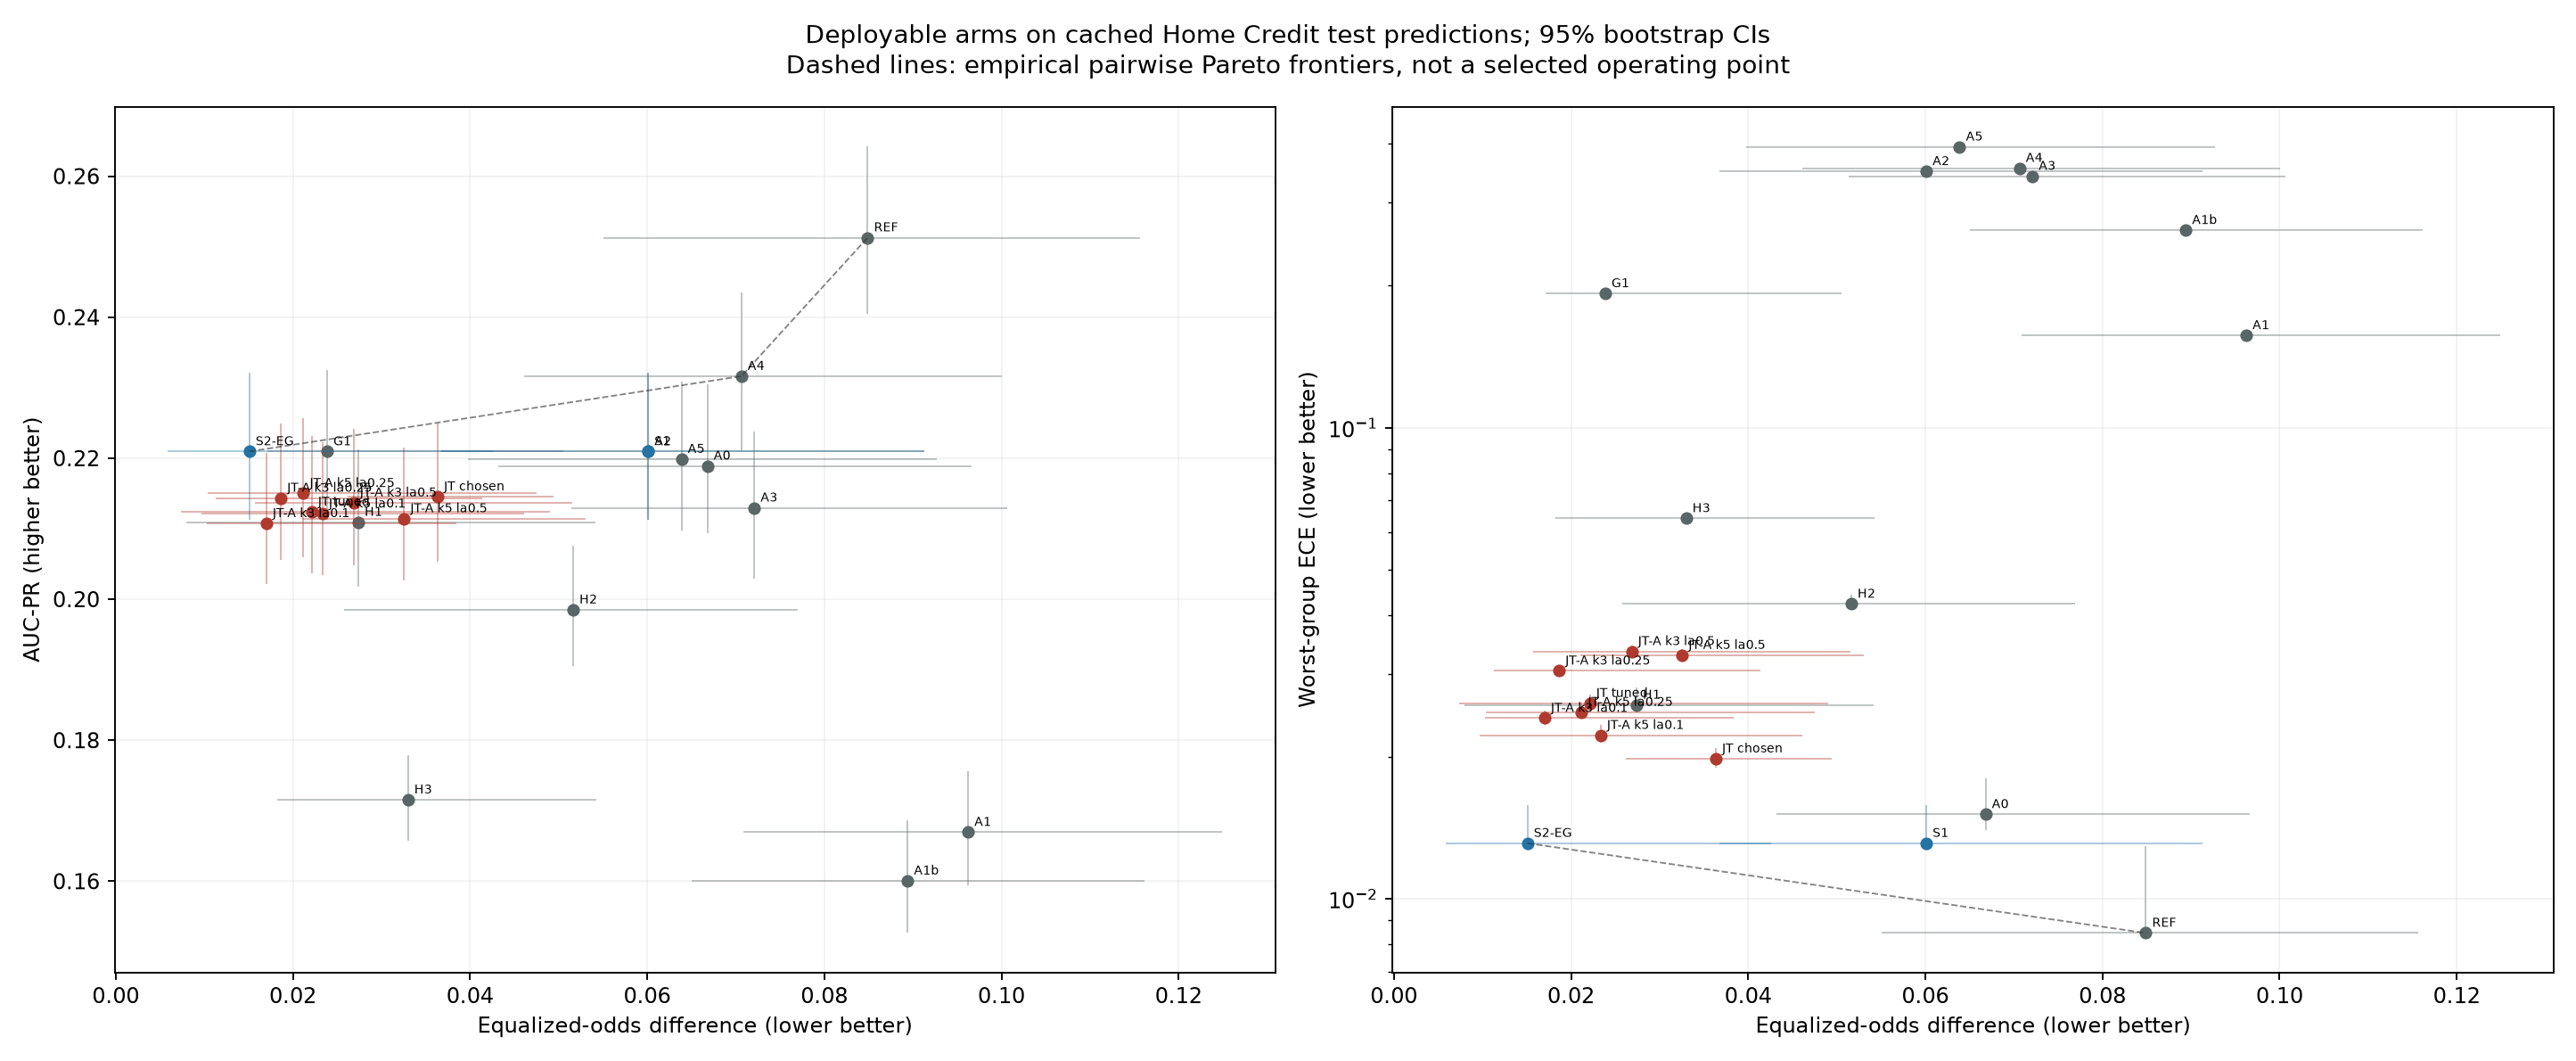

In [5]:
display(Image(filename=str(R / 'pareto_deployable.png')))

## 4. Paired differences on test (JT chosen minus each arm; H1 to H3 and tuned JT versus S2-EG; JT-A versus JT chosen)

In [6]:
d = pd.read_csv(R / 'paired_diffs_test.csv')
d[d.A == 'JT chosen'].pivot_table(index='B', columns='metric', values='diff_A_minus_B').round(4)

metric,auc_pr,auc_roc,dir,eod,recall,worst_group_ece
B,,,,,,
A0,-0.0046,-0.0006,0.0359,-0.0306,-0.0038,0.0041
A1,0.0473,0.0579,0.0471,-0.0596,0.0653,-0.1371
A1b,0.0542,0.0769,0.0480,-0.0529,0.0724,-0.2424
A2,-0.0065,-0.0029,0.0306,-0.0238,-0.0067,-0.3298
A3,0.0016,0.0190,0.0469,-0.0361,0.0076,-0.3216
A4,-0.0171,-0.0049,0.0404,-0.0344,-0.0139,-0.3353
A5,-0.0054,-0.0017,0.0324,-0.0275,-0.0031,-0.3742
G1,-0.0065,-0.0012,0.0115,0.0092,-0.0060,-0.1725
GI,-0.0178,-0.0057,0.0695,-0.0922,-0.0105,-0.3669


In [7]:
d[d.significant & (d.metric.isin(['eod','auc_pr','worst_group_ece']))].round(4).head(60)

,A,B,metric,diff_A_minus_B,ci_lo,ci_hi,significant
1,JT chosen,A0,auc_pr,-0.0046,-0.0084,-0.0009,True
2,JT chosen,A0,worst_group_ece,0.0041,0.0017,0.0062,True
7,JT chosen,A1,auc_pr,0.0473,0.0389,0.0555,True
8,JT chosen,A1,worst_group_ece,-0.1371,-0.1411,-0.1335,True
9,JT chosen,A1,eod,-0.0596,-0.0938,-0.0276,True
13,JT chosen,A1b,auc_pr,0.0542,0.0456,0.0626,True
14,JT chosen,A1b,worst_group_ece,-0.2424,-0.2469,-0.2381,True
15,JT chosen,A1b,eod,-0.0529,-0.0844,-0.0217,True
19,JT chosen,A2,auc_pr,-0.0065,-0.0103,-0.0029,True
20,JT chosen,A2,worst_group_ece,-0.3298,-0.3331,-0.3266,True


## 5. Validation vs test: where the selected point and JT were optimistic

In [8]:
v = pd.read_csv(R / 'val_vs_test.csv'); v[['arm','deployable','val_auc_pr','test_auc_pr','val_eod','test_eod','val_worst_group_ece','test_worst_group_ece']].round(4)

,arm,deployable,val_auc_pr,test_auc_pr,val_eod,test_eod,val_worst_group_ece,test_worst_group_ece
0,A0,True,0.2201,0.2189,0.0831,0.0668,0.0140,0.0151
1,A1,True,0.1653,0.1670,0.1133,0.0962,0.1548,0.1568
2,A1b,True,0.1586,0.1601,0.1026,0.0894,0.2593,0.2622
3,A2,True,0.2212,0.2209,0.0763,0.0601,0.3502,0.3496
4,A3,True,0.1992,0.2130,0.1051,0.0721,0.3415,0.3415
5,A4,True,0.2218,0.2316,0.0962,0.0706,0.3551,0.3552
6,A5,True,0.2192,0.2199,0.0890,0.0639,0.3929,0.3941
7,G1,True,0.2188,0.2209,0.0447,0.0239,0.1893,0.1925
8,GI,False,0.2234,0.2323,0.1647,0.1292,0.3875,0.3867
9,H1,True,0.2094,0.2109,0.0069,0.0274,0.0261,0.0258


## 6. Leakage 'after': fresh gender probe on frozen z (same protocol as the Phase 1 'before' probe)

In [9]:
la = pd.read_csv(R / 'leakage_after.csv'); before = json.loads((ROOT / 'artifacts/leakage/before.json').read_text())
print('Phase 1 before: gender from features, test AUC =', round(before['gender_from_features_auc'], 4))
la.round(4)

Phase 1 before: gender from features, test AUC = 0.9003


,arm,n_seeds,probe_lgbm_test_auc,probe_lgbm_test_sd,probe_logistic_test_auc,probe_lgbm_val_auc,shap_probe_test_auc_seed0,shap_method,before_gender_from_X_test_auc
0,A2,3,0.7911,0.0194,0.7435,0.7917,0.8010,shap.GradientExplainer,0.9003
1,JT chosen,3,0.8006,0.0049,0.7541,0.8006,0.8109,shap.GradientExplainer,0.9003
2,JT tuned,3,0.8162,0.0127,0.7671,0.8127,0.7848,shap.GradientExplainer,0.9003
3,JT-A k3 la0.1,5,0.7731,0.0080,0.6983,0.7698,0.7894,shap.GradientExplainer,0.9003
4,JT-A k3 la0.25,5,0.7676,0.0160,0.6882,0.7674,0.7972,shap.GradientExplainer,0.9003
5,JT-A k3 la0.5,5,0.7684,0.0184,0.7078,0.7665,0.7707,shap.GradientExplainer,0.9003
6,JT-A k5 la0.1,5,0.7703,0.0113,0.6780,0.7691,0.7824,shap.GradientExplainer,0.9003
7,JT-A k5 la0.25,5,0.7589,0.0122,0.6677,0.7564,0.7798,shap.GradientExplainer,0.9003
8,JT-A k5 la0.5,5,0.7596,0.0156,0.6907,0.7565,0.7998,shap.GradientExplainer,0.9003


## 7. SHAP-vector probe and new-proxy check

In [10]:
sp = json.loads((R / 'shap_proxy.json').read_text()); print(json.dumps({k: v for k, v in sp.items() if k != 'before_top15_proxy_features'}, indent=1)[:4000])

{
 "JT chosen": {
  "top_A": [
   "AMT_GOODS_PRICE",
   "EXT_SOURCE_3",
   "EXT_SOURCE_2",
   "AMT_CREDIT",
   "EXT_SOURCE_1",
   "AMT_INCOME_TOTAL",
   "CREDIT_INCOME_RATIO",
   "AMT_ANNUITY",
   "CREDIT_TERM",
   "YEARS_EMPLOYED",
   "ANNUITY_INCOME_RATIO",
   "EXT_SOURCE_1_MISSING",
   "AGE_YEARS",
   "ORGANIZATION_TYPE",
   "OCCUPATION_TYPE"
  ],
  "top_B": [
   "AMT_GOODS_PRICE",
   "EXT_SOURCE_3",
   "EXT_SOURCE_2",
   "AMT_CREDIT",
   "AMT_ANNUITY",
   "EXT_SOURCE_1",
   "EXT_SOURCE_1_MISSING",
   "CREDIT_TERM",
   "YEARS_EMPLOYED",
   "CREDIT_INCOME_RATIO",
   "FLAG_OWN_CAR",
   "ORGANIZATION_TYPE",
   "ANNUITY_INCOME_RATIO",
   "AGE_YEARS",
   "OCCUPATION_TYPE"
  ],
  "new_in_B": [
   "FLAG_OWN_CAR"
  ],
  "new_proxy_flags": {
   "FLAG_OWN_CAR": true
  },
  "new_gender_auc": {
   "FLAG_OWN_CAR": 0.6710045615312776
  },
  "top_B_in_before_top15": [
   "EXT_SOURCE_3",
   "EXT_SOURCE_2",
   "AMT_ANNUITY",
   "EXT_SOURCE_1",
   "CREDIT_TERM",
   "YEARS_EMPLOYED",
   "CREDIT_INCOME

## 8. Matched-pair check (nearest applicant of the other gender; model never sees gender)

In [11]:
pd.read_csv(R / 'matched_pair.csv').round(5)

,arm,mean,median,p95,max
0,A2,0.02970,0.01647,0.10582,0.32786
1,H1,0.02337,0.01555,0.07219,0.22472
2,H2,0.01361,0.01010,0.03837,0.12027
3,H3,0.00356,0.00288,0.00930,0.02260
4,JT-A k3 la0.1,0.03373,0.02251,0.10372,0.23178
5,JT-A k3 la0.25,0.03400,0.02137,0.10943,0.31655
6,JT-A k3 la0.5,0.03750,0.02233,0.12642,0.30864
7,JT-A k5 la0.1,0.03528,0.02163,0.11580,0.25931
8,JT-A k5 la0.25,0.03449,0.01889,0.12361,0.27238
9,JT-A k5 la0.5,0.03541,0.01938,0.12597,0.29411


## 9. Retrain checks (REF and GI reproduce their validation predictions)

In [12]:
pd.read_csv(R / 'retrain_check.csv')

,arm,seed,max_abs_val_prob_diff
0,REF,0,0.0
1,REF,1,0.0
2,REF,2,0.0
3,GI,0,0.0
4,GI,1,0.0
5,GI,2,0.0


## 10. UCI Taiwan: identical hyper-parameters and lambdas, SEX as gender, no re-tuning

In [13]:
TW = P6 / 'taiwan'
print(json.dumps(json.loads((TW / 'prep.json').read_text()), indent=1)[:1800])
print('gender from features (Taiwan):', json.dumps(json.loads((TW / 'taiwan_leak_before.json').read_text())))

{
 "odd_codes_mapped_to_0": {
  "EDUCATION": {
   "5": 280,
   "6": 51,
   "0": 14
  },
  "MARRIAGE": {
   "0": 54
  }
 },
 "cards": [
  6,
  5
 ],
 "class_weights": {
  "0": 0.6420055029043106,
  "1": 2.2604951560818085
 },
 "n_train": 21000,
 "n_val": 4500,
 "default_rate_train": 0.2211904761904762,
 "female_share_train": 0.6037142857142856,
 "gender_in_X": false,
 "hp": {
  "A0": {
   "lr": 0.0021528749054645644,
   "weight_decay": 0.0005072957033687832,
   "dropout": 0.028242643640234863,
   "emb_dim": 16
  },
  "A2": {
   "lr": 0.0026480792283380566,
   "weight_decay": 1.3549853367563292e-06,
   "dropout": 0.2534251886332105,
   "emb_dim": 16
  },
  "JT chosen": {
   "lr": 0.0026480792283380566,
   "weight_decay": 1.3549853367563292e-06,
   "dropout": 0.2534251886332105,
   "emb_dim": 16
  }
 },
 "jt_lambdas": [
  0.05,
  2.0,
  0.0
 ]
}
gender from features (Taiwan): {"seed_0": {"lgbm_val_auc": 0.661351813460914, "lgbm_test_auc": 0.643603216159818}, "seed_1": {"lgbm_val_auc": 0.6

In [14]:
tw = pd.read_csv(TW / 'taiwan_results.csv'); tw['use'] = np.where(tw.deployable, 'deployable', 'analysis only')
tw[tw.split == 'test'][['arm','use','rate','auc_roc','auc_pr','worst_group_ece','eod','dir','recall']].round(4)

,arm,use,rate,auc_roc,auc_pr,worst_group_ece,eod,dir,recall
1,A0,deployable,10% flag rate,0.7738,0.5458,0.0292,0.0289,0.9748,0.3216
3,A0,deployable,train default rate,0.7738,0.5458,0.0292,0.0386,0.9631,0.5327
5,A2,deployable,10% flag rate,0.7725,0.5368,0.2262,0.0288,0.9783,0.3162
7,A2,deployable,train default rate,0.7725,0.5368,0.2262,0.0346,0.9595,0.5256
9,S1,deployable,10% flag rate,0.7725,0.5368,0.0298,0.0288,0.9783,0.3162
11,S1,deployable,train default rate,0.7725,0.5368,0.0298,0.0346,0.9595,0.5256
13,S2-EG,deployable,10% flag rate,0.7725,0.5368,0.0298,0.0255,0.9798,0.3142
15,S2-EG,deployable,train default rate,0.7725,0.5368,0.0298,0.0350,0.9609,0.5270
17,S2-GT,analysis only,10% flag rate,0.7725,0.5368,0.0298,0.0542,0.9886,0.3122
19,S2-GT,analysis only,train default rate,0.7725,0.5368,0.0298,0.0289,0.9834,0.5206


In [15]:
pd.read_csv(TW / 'taiwan_zprobe_after.csv').groupby('arm').mean(numeric_only=True).round(4)

,seed,probe_lgbm_test_auc,probe_lgbm_val_auc,probe_logistic_test_auc,lgbm_best_iteration
arm,,,,,
A2,1.0,0.5858,0.5970,0.5796,44.3333
JT chosen,1.0,0.6004,0.5996,0.5839,50.3333


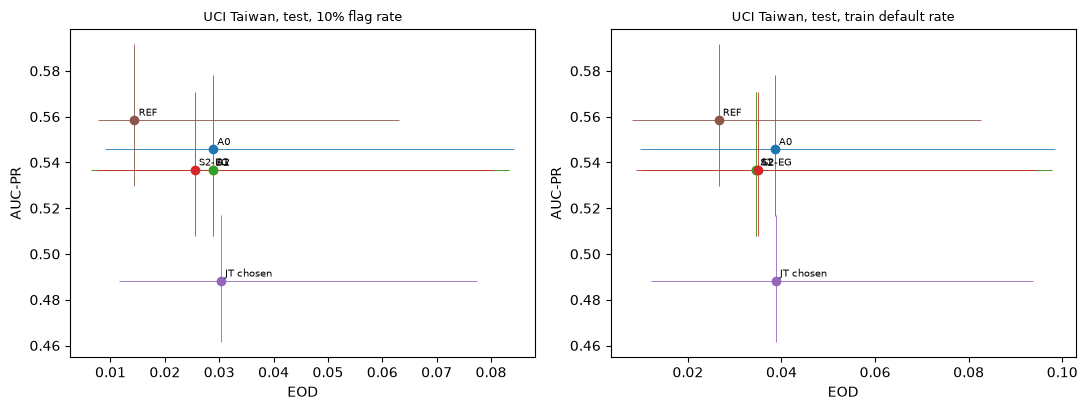

In [16]:
tt = tw[(tw.split == 'test') & tw.deployable]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, rn in zip(ax, ['10% flag rate', 'train default rate']):
    for _, r in tt[tt.rate == rn].iterrows():
        a.errorbar(r.eod, r.auc_pr, xerr=[[r.eod-r.eod_lo],[r.eod_hi-r.eod]], yerr=[[r.auc_pr-r.auc_pr_lo],[r.auc_pr_hi-r.auc_pr]], fmt='o', lw=0.6)
        a.annotate(r.arm, (r.eod, r.auc_pr), fontsize=7, xytext=(3, 3), textcoords='offset points')
    a.set_xlabel('EOD'); a.set_ylabel('AUC-PR'); a.set_title('UCI Taiwan, test, ' + rn, fontsize=9)
plt.tight_layout(); plt.show()

## 11. Soft flags and conclusions

See `artifacts/RUN_LOG.md` (Phase 6 entry) for the full list and the plain-language conclusions.

In [17]:
print('\n'.join(l for l in (ROOT / 'artifacts/RUN_LOG.md').read_text(encoding='utf-8').splitlines() if 'SOFT FLAG' in l)[-6000:])

> **SOFT FLAGS (overnight run, 2026-11-01; details in the Phase 6 RESULTS entry):** JT chosen does not beat the sequential baseline (S1/S2-EG) on fairness, calibration or AUC; its validation EOD was optimistic (0.0234 -> 0.0363 test); single-step GRL failed in the Phase 4 single-step runs (validation numbers, control probe 0.785): probe 0.67 to 0.81, adversary loss up to 8 to 16, AUC-ROC 0.46 to 0.73; JT chosen's test probe (0.801) has the adversary off and is not a GRL result; FLAG_OWN_CAR is a possible new proxy; matched-pair deltas not reduced; worst-group ECE of JT at the 0.02 cap; mixed SHAP sample sizes (4,000/5,000); Taiwan JT loses 0.05 AUC-PR; unauthorised Codex edits kept after review.
5. JT vs baselines (validation, 10% flag rate; AUC-ROC / AUC-PR / worst-group ECE / EOD / DIR / recall): A2 .7460/.2212/.350/.0763/.9455/.320; S1 .7460/.2212/.0123/.0763/.9455/.320; S2-EG .7460/.2212/.0123/.0325/.9727/.316; S2-GT (analysis only) .7460/.2212/.0123/.0051/.9871/.318; JT .7428/.214